# Notebook 02 — Fixed-setpoint PI cooling controller: design and verification

Baseline controller (PROJECT_SPEC §7.1, "FS-PI"). Code: `src/controllers.py`; plant: `src/thermal_model.py` (verified in notebook 01).

<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Scope</b><br>
One fixed-setpoint PI controller on the exact ZOH plant. There is <b>no</b> adaptive controller, optimisation, MPC, electricity calculation or energy-saving claim here. Every number is a model result with illustrative [ILL] parameters. Overload and low-load scenarios deliberately test failure behaviour: they make <b>no safety promise</b>.
</div>

<div style="background:#f1f1ef;border-left:6px solid #6b6b66;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>AI acknowledgement</b><br>
This notebook and <code>src/controllers.py</code> were drafted by Claude (Anthropic), used through Claude Code, at the team's request on 28 Oct 2026. The team must review them and be able to explain them. See <code>AI_USE_LOG.md</code>.
</div>

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..", "src").resolve()))
import thermal_model as tm
import controllers as ct

FIG_DIR = Path("..", "figures").resolve()
FIG_DIR.mkdir(exist_ok=True)
p = tm.Params()
H = 3600.0
TOL = 0.1  # tracking tolerance, K

results, findings = [], []


def record(cid, desc, value, criterion, passed):
    results.append((cid, desc, value, criterion, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {cid}: {desc}\n        measured: {value}   criterion: {criterion}")
    assert passed, f"{cid} failed"


def finding(fid, text):
    findings.append((fid, text))
    print(f"[FINDING] {fid}: {text}")


print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__}; Q_max = {p.Q_max/1e6:.2f} MW_th (illustrative)")

numpy 2.5.4, matplotlib 3.11.2; Q_max = 1.50 MW_th (illustrative)


## 1. Setpoint (PROJECT_SPEC §7.1)

$$T_{set} = \min\!\Big(T_{a,\max},\ T_{s,\max} - \frac{P_{IT,\max}}{UA_s}\Big) - m .$$

- $T_{a,\max}=27$ °C (upper edge of the recommended band, [SRC-5]).
- $T_{s,\max}=40$ °C is an **illustrative** limit on the lumped equipment temperature.
- $P_{IT,\max}=1.0$ MW is the largest load the controller is designed for. Overload tests deliberately exceed it.
- $m=1$ K is a **provisional** margin (spec decision D3). It is not tuned yet, because no energy calculation exists at this stage.

At 1.0 MW the server limit binds: $40 - 15 = 25$ °C, so $T_{set}=24.0$ °C.

In [2]:
T_SET = ct.setpoint_from_spec(p, P_IT_max=1.0e6, T_a_max=27.0, T_s_max=40.0, margin=1.0)
print(f"T_set = min(27, 40 - 1.0e6/UA_s) - 1 = min(27, {40 - 1e6/p.UA_s:.2f}) - 1 = {T_SET:.2f} degC")

T_set = min(27, 40 - 1.0e6/UA_s) - 1 = min(27, 25.00) - 1 = 24.00 degC


## 2. The PI law, its units and the exact update order
<div style="background:#e7f7f0;border-left:6px solid #1baf7a;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Update at each control time $t_k = k\,\Delta t$</b><br>
1. measure $T_a(t_k)$ from the exact plant state<br>2. error $e_k = T_a(t_k) - T_{set}$ (K). <b>Positive error = too warm = more cooling.</b><br>3. tentative integrator $I_{tent} = I_{k-1} + K_i\,\Delta t\,e_k$ (W$_{th}$)<br>4. tentative command $v = Q_{ff} + K_p e_k + I_{tent}$<br>5. <b>conditional integration</b>: if the update would push the command past a limit, i.e. ($v > Q_{\max}$ and $e_k>0$) or ($v < 0$ and $e_k<0$), integrate <i>only up to that limit</i>: $I_k=\max(I_{k-1},\,Q_{\max}-Q_{ff}-K_pe_k)$ (high) or $I_k=\min(I_{k-1},\,0-Q_{ff}-K_pe_k)$ (low). The integrator never moves past the boundary and never backwards; if the command was already beyond the limit, $I_k=I_{k-1}$ (fully blocked). Otherwise $I_k = I_{tent}$, so updates that move back out of saturation are always accepted. <b>Invariant:</b> whenever integration is limited, $Q_c$ is at that limit.<br>6. $Q_{c,k} = \mathrm{clip}(Q_{ff} + K_p e_k + I_k,\ 0,\ Q_{\max})$<br>7. hold $Q_{c,k}$ on $[t_k, t_k+\Delta t)$. The plant is propagated <b>exactly</b> (ZOH), with the interval split at every disturbance change and at a 5 s inspection grid.
</div>

**Units.**

| Quantity | Unit |
|---|---|
| $K_p$ | W$_{th}$ per K of error |
| $K_i$ | W$_{th}$ per (K·s) |
| $I$, $Q_{ff}$, $Q_c$ | W$_{th}$ |
| $\Delta t$ | s |

We use $Q_{ff}=0$.

**Consistent initialization.** The plant starts at the equilibrium with $T_a=T_{set}$ under the holding cooling $Q_0=P_{IT}+UA_e(T_{out}-T_{set})$. The integrator starts at $I=Q_0$, so $e_0=0$ and the first command is exactly $Q_0$ (a "bumpless" start).

### 2a. Anti-windup unit tests: both directions
Each case gives the exact integrator value and command that the rule must produce.

Case AW5 is a **regression test**. An earlier draft of this controller rejected the *whole* integrator update instead of clamping it at the limit. With $K_p=0$, that froze the integrator at a positive value while the room was too cold: cooling stayed on, and in scenario S5 the air was driven far below the band. The current rule must drive the command to exactly 0 in that situation.

In [3]:
g_a = ct.PIGains(Kp=1e4, Ki=500.0, dt=60.0)     # Ki*dt = 3e4 W/K
g_b = ct.PIGains(Kp=0.0, Ki=199.5, dt=300.0)    # integral-only, as selected at 300 s
Qmin, Qmax = 0.0, p.Q_max
# (description, gains, I_prev, e, anti_windup, expected I_new, expected Q_c, expect limited)
cases = [
    ("high, already beyond limit, e>0: fully blocked", g_a, 1.6e6, +1.0, True, 1.6e6, Qmax, True),
    ("high, crossing from inside, e>0: clamped so command = Q_max", g_a, 1.47e6, +1.0, True, Qmax - 1e4, Qmax, True),
    ("high, e<0 (coming out): full update", g_a, 1.6e6, -0.5, True, 1.6e6 - 1.5e4, Qmax, False),
    ("low, already beyond limit, e<0: fully blocked", g_a, -1e5, -1.0, True, -1e5, 0.0, True),
    ("low, crossing from inside, Kp=0 (regression): clamped so command = 0", g_b, 6.7e4, -3.0, True, 0.0, 0.0, True),
    ("low, e>0 (coming out): full update", g_a, -1e5, +0.5, True, -1e5 + 1.5e4, 0.0, False),
    ("unsaturated: full update", g_a, 8e5, +0.2, True, 8e5 + 6e3, 8e5 + 6e3 + 2e3, False),
    ("anti-windup OFF, high, e>0: integrates anyway", g_a, 1.6e6, +1.0, False, 1.63e6, Qmax, False),
]
for i, (desc, g, I_prev, e, aw, I_exp, u_exp, lim_exp) in enumerate(cases, start=1):
    u, I_new, info = ct.pi_update(I_prev, e, g, 0.0, Qmin, Qmax, anti_windup=aw)
    ok = np.isclose(I_new, I_exp, rtol=0, atol=1e-6) and np.isclose(u, u_exp, rtol=0, atol=1e-6) and info["limited"] == lim_exp
    record(f"AW{i}", desc, f"I {I_prev:.6g} -> {I_new:.6g} W, Q_c = {u:.6g} W, limited={info['limited']}",
           f"I = {I_exp:.6g}, Q_c = {u_exp:.6g}, limited={lim_exp}", ok)

[PASS] AW1: high, already beyond limit, e>0: fully blocked
        measured: I 1.6e+06 -> 1.6e+06 W, Q_c = 1.5e+06 W, limited=True   criterion: I = 1.6e+06, Q_c = 1.5e+06, limited=True
[PASS] AW2: high, crossing from inside, e>0: clamped so command = Q_max
        measured: I 1.47e+06 -> 1.49e+06 W, Q_c = 1.5e+06 W, limited=True   criterion: I = 1.49e+06, Q_c = 1.5e+06, limited=True
[PASS] AW3: high, e<0 (coming out): full update
        measured: I 1.6e+06 -> 1.585e+06 W, Q_c = 1.5e+06 W, limited=False   criterion: I = 1.585e+06, Q_c = 1.5e+06, limited=False
[PASS] AW4: low, already beyond limit, e<0: fully blocked
        measured: I -100000 -> -100000 W, Q_c = 0 W, limited=True   criterion: I = -100000, Q_c = 0, limited=True
[PASS] AW5: low, crossing from inside, Kp=0 (regression): clamped so command = 0
        measured: I 67000 -> 0 W, Q_c = 0 W, limited=True   criterion: I = 0, Q_c = 0, limited=True
[PASS] AW6: low, e>0 (coming out): full update
        measured: I -100000 -> -85

## 3. Discrete closed-loop poles and gain design

Below saturation the loop is linear. With $z_k=[T_s(t_k),\,T_a(t_k),\,I_{k-1}]^\top$ and the update order above,

$$z_{k+1} = M z_k + (\text{reference and disturbance terms}),\qquad
M=\begin{bmatrix}\Phi + (K_p+K_i\Delta t)\,\Gamma_u c & \Gamma_u\\ K_i\Delta t\,c & 1\end{bmatrix},\quad c=[0\ \ 1].$$

Here $\Phi$ and $\Gamma_u$ are the exact ZOH matrices for one interval $\Delta t$. The loop is stable if and only if every eigenvalue of $M$ lies **inside the unit circle**.

**Design rule (applied separately at each $\Delta t$).** Over a grid, $K_p\in\{0\}\cup[10^3,3\times10^5]$ W/K and $K_i\in[1,10^4]$ W/(K·s), choose the pair that:

- minimizes the spectral radius $\rho(M)$, the slowest decay per step;
- **subject to** the loop staying stable with both gains doubled (gain margin 2, a guard against model error).

This rule is a property of the linear loop only. It ignores saturation and intersample behaviour, which the simulations test separately.

In [4]:
Kp_grid = np.concatenate([[0.0], np.geomspace(1e3, 3e5, 31)])
Ki_grid = np.geomspace(1.0, 1e4, 41)

g60, info60 = ct.design_gains(p, 60.0, Kp_grid, Ki_grid, gain_margin=2.0)
poles60 = ct.closed_loop_poles(p, g60)
print(f"dt = 60 s design:  Kp = {g60.Kp:.1f} W/K,  Ki = {g60.Ki:.2f} W/(K s)  (Ki*dt = {g60.Ki*g60.dt:.0f} W/K)")
print(f"  poles = {np.round(poles60, 5)},  |poles| = {np.round(np.abs(poles60), 5)}")
print(f"  grid-edge flags: Kp {info60['Kp_edge']}, Ki {info60['Ki_edge']};  feasible pairs {info60['n_feasible']}")
record("P1", "60 s: unsaturated closed-loop poles inside unit circle", f"rho = {info60['rho']:.4f}", "< 1", info60["rho"] < 1)
record("P2", "60 s: still stable with both gains doubled", f"rho = {info60['rho_margin']:.4f}", "< 1", info60["rho_margin"] < 1)

g60_at_300 = ct.PIGains(g60.Kp, g60.Ki, 300.0)
rho_bad = ct.spectral_radius(p, g60_at_300)
finding("F1", f"the 60 s gains used at dt = 300 s give rho = {rho_bad:.3f} (> 1): UNSTABLE, so retuning is required")

g300, info300 = ct.design_gains(p, 300.0, Kp_grid, Ki_grid, gain_margin=2.0)
poles300 = ct.closed_loop_poles(p, g300)
print(f"\ndt = 300 s RETUNED:  Kp = {g300.Kp:.1f} W/K,  Ki = {g300.Ki:.2f} W/(K s)  (Ki*dt = {g300.Ki*g300.dt:.0f} W/K)")
print(f"  poles = {np.round(poles300, 5)},  |poles| = {np.round(np.abs(poles300), 5)}")
print(f"  grid-edge flags: Kp {info300['Kp_edge']}, Ki {info300['Ki_edge']};  feasible pairs {info300['n_feasible']}")
record("P3", "300 s retuned: unsaturated closed-loop poles inside unit circle", f"rho = {info300['rho']:.4f}", "< 1", info300["rho"] < 1)
record("P4", "300 s retuned: still stable with both gains doubled", f"rho = {info300['rho_margin']:.4f}", "< 1", info300["rho_margin"] < 1)
if info300["Kp_edge"] == "low" and g300.Kp == 0.0:
    finding("F2", "at dt = 300 s the rule selects Kp = 0 (integral action only). This is the physical limit Kp >= 0, "
                  "not a grid-width artefact. Reason: the fast mode (46 s) settles within one 300 s interval, so the "
                  "sampled plant is almost static and proportional action adds no damping")
if info60["Kp_edge"] or info60["Ki_edge"] or info300["Ki_edge"]:
    finding("F3", "a design optimum lies on a grid edge other than Kp = 0; widen the grid")

static_gain = 1.0 / (p.UA_s + p.UA_e)
print(f"\nfor intuition: quasi-static air gain 1/(UA_s+UA_e) = {static_gain:.3e} K/W, so 1/gain = {1/static_gain/1e3:.1f} kW/K;"
      f" compare Kp + Ki*dt = {(g60.Kp + g60.Ki*60)/1e3:.1f} kW/K (60 s) and {(g300.Kp + g300.Ki*300)/1e3:.1f} kW/K (300 s)")
GAINS = {60: g60, 300: g300}

dt = 60 s design:  Kp = 8096.1 W/K,  Ki = 630.96 W/(K s)  (Ki*dt = 37857 W/K)
  poles = [0.68608+0.01011j 0.68608-0.01011j 0.43013+0.j     ],  |poles| = [0.68616 0.68616 0.43013]
  grid-edge flags: Kp None, Ki None;  feasible pairs 773
[PASS] P1: 60 s: unsaturated closed-loop poles inside unit circle
        measured: rho = 0.6862   criterion: < 1
[PASS] P2: 60 s: still stable with both gains doubled
        measured: rho = 0.8277   criterion: < 1
[FINDING] F1: the 60 s gains used at dt = 300 s give rho = 2.711 (> 1): UNSTABLE, so retuning is required



dt = 300 s RETUNED:  Kp = 0.0 W/K,  Ki = 199.53 W/(K s)  (Ki*dt = 59858 W/K)
  poles = [0.35498+0.43938j 0.35498-0.43938j 0.00474+0.j     ],  |poles| = [0.56486 0.56486 0.00474]
  grid-edge flags: Kp low, Ki None;  feasible pairs 420
[PASS] P3: 300 s retuned: unsaturated closed-loop poles inside unit circle
        measured: rho = 0.5649   criterion: < 1
[PASS] P4: 300 s retuned: still stable with both gains doubled
        measured: rho = 0.9181   criterion: < 1
[FINDING] F2: at dt = 300 s the rule selects Kp = 0 (integral action only). This is the physical limit Kp >= 0, not a grid-width artefact. Reason: the fast mode (46 s) settles within one 300 s interval, so the sampled plant is almost static and proportional action adds no damping

for intuition: quasi-static air gain 1/(UA_s+UA_e) = 1.456e-05 K/W, so 1/gain = 68.7 kW/K; compare Kp + Ki*dt = 46.0 kW/K (60 s) and 59.9 kW/K (300 s)


## 4. Test scenarios

All scenarios start at equilibrium with $T_a=T_{set}=24$ °C. Disturbances are piecewise constant with **explicit** change times.

| ID | What happens | Purpose |
|---|---|---|
| S1 | IT load 0.6 → **1.0 MW** at 1 h → **0.6 MW** at 9 h; $T_{out}=30$ °C; 17 h total | Load tracking and settling |
| S2 | $T_{out}$ 30 → **35 °C** at 1 h; load 0.8 MW; 9 h | Outdoor disturbance |
| S3 | Load 1.0 → **1.7 MW** (above $Q_{\max}=1.5$ MW) at 1 h, back to 1.0 MW at **1 h 20 min 30 s** (4830 s, deliberately *between* control updates); 9 h; anti-windup on and off | Upper saturation, anti-windup, recovery |
| S4 | Load 1.0 → **2.0 MW** for 1 h | Severe overload. Expected to leave the COP domain, which stops the run |
| S5 | *Artificial* mechanism test: load 0.6 → **0** and $T_{out}$ 30 → **20 °C** at 1 h, both back at 5 h; anti-windup on and off | Lower saturation ($Q_c=0$) |

**Tracking tolerance ±0.1 K.**

- **Settling time:** time after a disturbance change after which $|T_a-T_{set}|\le 0.1$ K for the rest of that window, measured on the fine intersample grid.
- **Overshoot:** the largest swing past the setpoint, on the opposite side from the main deviation.
- **Residual tracking error:** reported as the actual value at the end of the window and the maximum over its last hour, not as "zero".

In [5]:
PD = ct.PiecewiseDisturbance
SC = {
    "S1": dict(dist=PD([0, 1*H, 9*H], [0.6e6, 1.0e6, 0.6e6], [30.0, 30.0, 30.0]), t_end=17*H,
               events=[(1*H, 9*H, "load 0.6->1.0 MW"), (9*H, 17*H, "load 1.0->0.6 MW")]),
    "S2": dict(dist=PD([0, 1*H], [0.8e6, 0.8e6], [30.0, 35.0]), t_end=9*H, events=[(1*H, 9*H, "T_out 30->35 C")]),
    "S3": dict(dist=PD([0, 1*H, 4830.0], [1.0e6, 1.7e6, 1.0e6], [30.0, 30.0, 30.0]), t_end=9*H,
               events=[(1*H, 4830.0, "overload 1.7 MW"), (4830.0, 9*H, "after overload (1.0 MW)")]),
    "S4": dict(dist=PD([0, 1*H, 2*H], [1.0e6, 2.0e6, 1.0e6], [30.0, 30.0, 30.0]), t_end=9*H,
               events=[(1*H, 2*H, "overload 2.0 MW"), (2*H, 9*H, "after overload (1.0 MW)")]),
    "S5": dict(dist=PD([0, 1*H, 5*H], [0.6e6, 0.0, 0.6e6], [30.0, 20.0, 30.0]), t_end=13*H,
               events=[(1*H, 5*H, "idle + T_out 20 C"), (5*H, 13*H, "back to 0.6 MW, 30 C")]),
}


def run(sid, gains, aw=True, fine_dt=5.0, t_end=None):
    s = SC[sid]
    P0, To0 = s["dist"].at(0.0)
    Q0 = tm.holding_cooling(p, T_SET, P0, To0)
    x0 = tm.equilibrium(p, Q0, P0, To0)
    ctrl = ct.FixedSetpointPI(gains, T_SET, Q_min=0.0, Q_max=p.Q_max, anti_windup=aw)
    ctrl.initialize(Q0)
    res = ct.simulate_closed_loop(p, ctrl, s["dist"], x0, t_end or s["t_end"], fine_dt=fine_dt)
    res.meta["x0"] = x0
    return res


R = {}
for dt, g in GAINS.items():
    for sid in SC:
        R[(sid, dt, True)] = run(sid, g, aw=True)
    for sid in ("S3", "S5"):
        R[(sid, dt, False)] = run(sid, g, aw=False)
for key, res in R.items():
    print(f"{key[0]} dt={key[1]:3d}s AW={'on ' if key[2] else 'off'}: {res.status:20s} {res.message}")

S1 dt= 60s AW=on : completed            
S2 dt= 60s AW=on : completed            
S3 dt= 60s AW=on : completed            
S4 dt= 60s AW=on : stopped_cop_domain   COP model outside its domain: lift 13.396 K < required 13.399 K
S5 dt= 60s AW=on : completed            
S3 dt= 60s AW=off: completed            
S5 dt= 60s AW=off: stopped_cop_domain   temperature lift T_cd - T_ev must be > 0 K; got -0.97 K
S1 dt=300s AW=on : completed            
S2 dt=300s AW=on : completed            
S3 dt=300s AW=on : completed            
S4 dt=300s AW=on : stopped_cop_domain   COP model outside its domain: lift 13.332 K < required 13.402 K
S5 dt=300s AW=on : completed            
S3 dt=300s AW=off: completed            
S5 dt=300s AW=off: stopped_cop_domain   temperature lift T_cd - T_ev must be > 0 K; got -11.63 K


## 5. Verification of the closed-loop simulator

1. **I1, consistent initialization:** with no disturbance change, the loop must stay at its starting equilibrium.
2. **L1, linear recursion = simulator:** in the unsaturated scenario S2, iterating $z_{k+1}=Mz_k+\dots$ must reproduce the simulator at every update. This ties the pole analysis to the code that produces the plots.
3. **R1, independent replay:** feed the logged $Q_c$ sequence and the disturbances back into notebook 01's `solve_ivp` reference, restarted at every update *and* at every disturbance change (including the off-grid change at 4830 s in S3). It must match the closed-loop trajectory.
4. **E1, energy balance:** must hold on closed-loop runs.
5. **G1, fine-grid refinement:** intersample extrema found on the 5 s grid must agree with a 1 s grid.

In [6]:
for dt, g in GAINS.items():
    flat = PD([0.0], [0.8e6], [30.0])
    Q0 = tm.holding_cooling(p, T_SET, 0.8e6, 30.0); x0 = tm.equilibrium(p, Q0, 0.8e6, 30.0)
    c0 = ct.FixedSetpointPI(g, T_SET, Q_max=p.Q_max); c0.initialize(Q0)
    r0 = ct.simulate_closed_loop(p, c0, flat, x0, 6*H)
    drift = np.max(np.abs(r0.X[:, :2] - x0)); dQ = np.max(np.abs(r0.log["u"] - Q0))
    # round-off is amplified by the gains (Kp + Ki*dt ~ 5e4 W/K) and accumulated by the integrator,
    # so the cooling drift is judged relative to Q0
    record(f"I1-{dt}", f"dt={dt}s: no disturbance -> stays at start equilibrium (6 h)",
           f"max |dT| {drift:.1e} K, max |dQ|/Q0 {dQ/Q0:.1e}", "< 1e-8 K, < 1e-9", drift < 1e-8 and dQ / Q0 < 1e-9)

    # L1: linear recursion with M vs simulator, S2 (must be unsaturated)
    res = R[("S2", dt, True)]
    M = ct.closed_loop_matrix(p, g)
    Phi, Gam = tm.zoh_step_matrices(p, g.dt)
    Gu, Gd = Gam[:2, :1], Gam[:2, 1:3]
    kd = g.Kp + g.Ki * g.dt
    z = np.r_[res.meta["x0"], tm.holding_cooling(p, T_SET, 0.8e6, 30.0)]
    err = 0.0
    for k, tk in enumerate(res.log["t"]):
        err = max(err, abs(z[0] - res.log["T_s"][k]), abs(z[1] - res.log["T_a"][k]))
        d = np.array(SC["S2"]["dist"].at(tk))
        aff = np.r_[(Gu[:, 0] * (0.0 - kd * T_SET) + Gd @ d), -g.Ki * g.dt * T_SET]
        z = M @ z + aff
    unsat = np.all(res.log["sat"] == 0)
    # both computations are exact; the difference is accumulated round-off (one 60/300 s step vs 5 s sub-steps)
    record(f"L1-{dt}", f"dt={dt}s: linear closed-loop recursion (poles model) = simulator, S2",
           f"max |dT| {err:.1e} K, unsaturated={unsat}", "< 1e-8 K and no saturation", err < 1e-8 and unsat)

    # R1: replay logged inputs through solve_ivp, split at updates and disturbance changes
    for sid in ("S3", "S1"):
        res = R[(sid, dt, True)]
        bks = np.unique(np.concatenate([res.log["t"], SC[sid]["dist"].times, [res.t[-1]]]))
        bks = bks[bks <= res.t[-1]]
        idx = np.searchsorted(res.t, bks)
        assert np.allclose(res.t[idx], bks)
        W = np.column_stack([res.Q[idx[:-1]], res.P_IT[idx[:-1]], res.T_out[idx[:-1]]])
        Xr = tm.simulate_ivp(p, res.meta["x0"], bks, W)
        dT = np.max(np.abs(Xr[:, :2] - res.X[idx, :2]))
        record(f"R1-{sid}-{dt}", f"dt={dt}s: {sid} closed-loop trajectory vs independent solve_ivp replay "
               f"({len(bks)-1} pieces{', incl. off-grid change at 4830 s' if sid == 'S3' else ''})",
               f"{dT:.1e} K", "< 1e-6 K", dT < 1e-6)

    res = R[("S1", dt, True)]
    rel = abs(tm.energy_balance_residual(p, res.X)) / res.X[-1, 3]
    record(f"E1-{dt}", f"dt={dt}s: energy balance on closed-loop S1", f"{rel:.1e}", "< 1e-9", rel < 1e-9)

    fine1 = run("S1", g, fine_dt=1.0)
    d_ext = max(abs(fine1.X[:, 1].max() - res.X[:, 1].max()), abs(fine1.X[:, 1].min() - res.X[:, 1].min()),
                abs(fine1.X[:, 0].max() - res.X[:, 0].max()))
    record(f"G1-{dt}", f"dt={dt}s: S1 extrema on 5 s vs 1 s inspection grid", f"{d_ext:.1e} K", "< 0.01 K", d_ext < 0.01)

[PASS] I1-60: dt=60s: no disturbance -> stays at start equilibrium (6 h)
        measured: max |dT| 5.2e-10 K, max |dQ|/Q0 4.2e-11   criterion: < 1e-8 K, < 1e-9
[PASS] L1-60: dt=60s: linear closed-loop recursion (poles model) = simulator, S2
        measured: max |dT| 1.4e-09 K, unsaturated=True   criterion: < 1e-8 K and no saturation


[PASS] R1-S3-60: dt=60s: S3 closed-loop trajectory vs independent solve_ivp replay (541 pieces, incl. off-grid change at 4830 s)
        measured: 1.6e-08 K   criterion: < 1e-6 K


[PASS] R1-S1-60: dt=60s: S1 closed-loop trajectory vs independent solve_ivp replay (1020 pieces)
        measured: 3.9e-08 K   criterion: < 1e-6 K
[PASS] E1-60: dt=60s: energy balance on closed-loop S1
        measured: 6.3e-11   criterion: < 1e-9


[PASS] G1-60: dt=60s: S1 extrema on 5 s vs 1 s inspection grid
        measured: 6.8e-10 K   criterion: < 0.01 K
[PASS] I1-300: dt=300s: no disturbance -> stays at start equilibrium (6 h)
        measured: max |dT| 5.3e-10 K, max |dQ|/Q0 4.2e-11   criterion: < 1e-8 K, < 1e-9
[PASS] L1-300: dt=300s: linear closed-loop recursion (poles model) = simulator, S2
        measured: max |dT| 1.4e-09 K, unsaturated=True   criterion: < 1e-8 K and no saturation


[PASS] R1-S3-300: dt=300s: S3 closed-loop trajectory vs independent solve_ivp replay (109 pieces, incl. off-grid change at 4830 s)
        measured: 1.5e-08 K   criterion: < 1e-6 K


[PASS] R1-S1-300: dt=300s: S1 closed-loop trajectory vs independent solve_ivp replay (204 pieces)
        measured: 3.9e-08 K   criterion: < 1e-6 K
[PASS] E1-300: dt=300s: energy balance on closed-loop S1
        measured: 6.3e-11   criterion: < 1e-9


[PASS] G1-300: dt=300s: S1 extrema on 5 s vs 1 s inspection grid
        measured: 6.3e-05 K   criterion: < 0.01 K


### 5b. Saturation, anti-windup and COP-domain behaviour in closed loop
These checks read the logs of S3 and S5 (upper and lower saturation) and S4 (severe overload).

- **Anti-windup on:** every update that would push the command past a limit was limited, and the applied $Q_c$ was then at that limit. No update moving back out of saturation was limited.
- **Invariant, over every anti-windup-on run:** whenever integration was limited, $Q_c$ equalled the corresponding limit. This check would have caught the earlier draft's "frozen just inside the limit" flaw.
- **Anti-windup off:** integration is never limited.
- **S4:** if the COP leaves its domain, the run must stop at that point with the error recorded. Every point kept before the stop must be inside the domain.

In [7]:
for dt in GAINS:
    for sid, side in (("S3", "high"), ("S5", "low")):
        lg = R[(sid, dt, True)].log
        limit = p.Q_max if side == "high" else 0.0
        if side == "high":
            deeper = (lg["v_tent"] > p.Q_max) & (lg["e"] > 0)
            out = (lg["v_tent"] > p.Q_max) & (lg["e"] < 0)
        else:
            deeper = (lg["v_tent"] < 0) & (lg["e"] < 0)
            out = (lg["v_tent"] < 0) & (lg["e"] > 0)
        ok_lim = np.all(lg["limited"][deeper]) and np.allclose(lg["u"][deeper], limit, rtol=0, atol=1e-3)
        ok_out = not np.any(lg["limited"][out])
        record(f"AWc-{sid}-{dt}", f"dt={dt}s: {sid} {side} saturation: {deeper.sum()} deeper updates limited with Q_c at "
               f"the limit; {out.sum()} coming-out updates unlimited", f"limited+at limit={ok_lim}, coming-out ok={ok_out}",
               "both True", ok_lim and ok_out and deeper.sum() > 0)
        lg_off = R[(sid, dt, False)].log
        record(f"AWoff-{sid}-{dt}", f"dt={dt}s: {sid} anti-windup off never limits integration",
               f"{int(lg_off['limited'].sum())} limited", "0", lg_off["limited"].sum() == 0)

    n_lim, n_bad = 0, 0
    for key, res in R.items():
        if key[1] == dt and key[2]:
            lg = res.log
            lim = lg["limited"]
            at_limit = np.isclose(lg["u"], p.Q_max, rtol=0, atol=1e-3) | np.isclose(lg["u"], 0.0, rtol=0, atol=1e-3)
            n_lim += int(lim.sum()); n_bad += int(np.sum(lim & ~at_limit))
    record(f"AWinv-{dt}", f"dt={dt}s: invariant over all AW-on runs: limited integration => Q_c at a limit",
           f"{n_lim} limited updates, {n_bad} not at a limit", "0 not at a limit", n_bad == 0 and n_lim > 0)

    r4 = R[("S4", dt, True)]
    stopped = r4.status == "stopped_cop_domain"
    if stopped:
        prior_ok = all(ct._cop_ok(p, Ta, To) for Ta, To, Q in zip(r4.X[:-1, 1], r4.T_out[:-1], r4.Q[:-1]) if Q > 0)
        last_bad = not ct._cop_ok(p, r4.X[-1, 1], r4.T_out[-2])
        record(f"COP-{dt}", f"dt={dt}s: S4 stopped at first COP-domain violation, at t = {r4.stop_time/H:.3f} h "
               f"(T_a = {r4.X[-1,1]:.2f} degC)", f"earlier points valid={prior_ok}, last point invalid={last_bad}",
               "both True", prior_ok and last_bad)
        print("        logged error:", r4.message)
    else:
        finding(f"F-COP-{dt}", f"S4 at dt={dt}s did not leave the COP domain")

[PASS] AWc-S3-60: dt=60s: S3 high saturation: 20 deeper updates limited with Q_c at the limit; 0 coming-out updates unlimited
        measured: limited+at limit=True, coming-out ok=True   criterion: both True
[PASS] AWoff-S3-60: dt=60s: S3 anti-windup off never limits integration
        measured: 0 limited   criterion: 0
[PASS] AWc-S5-60: dt=60s: S5 low saturation: 225 deeper updates limited with Q_c at the limit; 0 coming-out updates unlimited
        measured: limited+at limit=True, coming-out ok=True   criterion: both True
[PASS] AWoff-S5-60: dt=60s: S5 anti-windup off never limits integration
        measured: 0 limited   criterion: 0
[PASS] AWinv-60: dt=60s: invariant over all AW-on runs: limited integration => Q_c at a limit
        measured: 256 limited updates, 0 not at a limit   criterion: 0 not at a limit
[PASS] COP-60: dt=60s: S4 stopped at first COP-domain violation, at t = 1.265 h (T_a = 36.60 degC)
        measured: earlier points valid=True, last point invalid=True   cr

## 6. Metrics at both sample periods
All extrema are taken on the **fine intersample grid** (5 s). For comparison, the values seen only at control-update times are listed separately.

Temperature limits used for reporting:

- 18–27 °C for $T_a$ ([SRC-5], secondary sources);
- 40 °C for $T_s$ (illustrative).

Violations are reported as hours outside a limit and degree-hours (K·h).

In [8]:
def fmt_settle(s):
    return "not settled in window" if s is None else f"{s/60:.1f} min"


TXT = []
for dt in GAINS:
    TXT.append(f"===== dt = {dt} s  (Kp = {GAINS[dt].Kp:.1f} W/K, Ki = {GAINS[dt].Ki:.2f} W/(K s)) =====")
    for sid in SC:
        for aw in ((True, False) if sid in ("S3", "S5") else (True,)):
            res = R[(sid, dt, aw)]
            tag = f"{sid}{'' if sid not in ('S3', 'S5') else (' AW on' if aw else ' AW off')}"
            stat = "" if res.status == "completed" else f"  ** STOPPED at {res.stop_time/H:.3f} h: COP outside domain **"
            TXT.append(f"{tag}{stat}")
            for (t0, t1, label) in SC[sid]["events"]:
                m = ct.event_metrics(res, t0, t1, tol=TOL)
                if not m["reached"]:
                    TXT.append(f"   [{label}] not reached (run stopped)")
                    continue
                TXT.append(f"   [{label}] peak dev {m['peak_dev']:+.3f} K, overshoot {m['overshoot']:.3f} K, "
                           f"settling (+/-{TOL} K) {fmt_settle(m['settling_time'])}, "
                           f"err at end {m['final_err']:+.1e} K, max|err| last h {m['max_err_last_hour']:.1e} K"
                           f"{' (window truncated)' if m['truncated'] else ''}")
            v, s = ct.limit_violations(res), ct.saturation_summary(res)
            upd_Ta = (res.log["T_a"].min(), res.log["T_a"].max())
            TXT.append(f"   T_a {v['T_a_min']:.2f}..{v['T_a_max']:.2f} C (update times only: {upd_Ta[0]:.2f}..{upd_Ta[1]:.2f}); "
                       f"T_s max {v['T_s_max']:.2f} C")
            TXT.append(f"   saturation: at Q_max {s['high_time']/60:.0f} min (longest {s['longest_high']/60:.0f}), "
                       f"at 0 {s['low_time']/60:.0f} min (longest {s['longest_low']/60:.0f}); limited updates {s['limited_updates']} (fully blocked {s['blocked_updates']}); "
                       f"integrator range {s['I_min']/1e6:+.3f}..{s['I_max']/1e6:+.3f} MW")
            viol = [f"T_a>27: {v['T_a_above_max_h']:.2f} h / {v['T_a_above_max_Kh']:.2f} Kh" if v['T_a_above_max_h'] else "",
                    f"T_a<18: {v['T_a_below_min_h']:.2f} h / {v['T_a_below_min_Kh']:.2f} Kh" if v['T_a_below_min_h'] else "",
                    f"T_s>40: {v['T_s_above_max_h']:.2f} h / {v['T_s_above_max_Kh']:.2f} Kh" if v['T_s_above_max_h'] else ""]
            viol = [x for x in viol if x]
            TXT.append(f"   limit violations: {'; '.join(viol) if viol else 'none'}")
print("\n".join(TXT))

# what the unstable 60 s gains do at 300 s (demonstration only)
bad = run("S1", g60_at_300)
sb, vb = ct.saturation_summary(bad), ct.limit_violations(bad)
finding("F4", f"S1 with the 60 s gains at dt = 300 s: status {bad.status}"
        f"{' at ' + format(bad.stop_time/H, '.2f') + ' h' if bad.status != 'completed' else ''}; "
        f"time at Q_max {sb['high_time']/60:.0f} min, at 0 {sb['low_time']/60:.0f} min; T_a {vb['T_a_min']:.1f}..{vb['T_a_max']:.1f} C")

===== dt = 60 s  (Kp = 8096.1 W/K, Ki = 630.96 W/(K s)) =====
S1
   [load 0.6->1.0 MW] peak dev +1.315 K, overshoot 0.000 K, settling (+/-0.1 K) 15.5 min, err at end +2.6e-12 K, max|err| last h 2.6e-12 K
   [load 1.0->0.6 MW] peak dev -1.315 K, overshoot 0.000 K, settling (+/-0.1 K) 15.5 min, err at end +2.6e-12 K, max|err| last h 2.6e-12 K
   T_a 22.68..25.32 C (update times only: 22.68..25.32); T_s max 39.00 C
   saturation: at Q_max 0 min (longest 0), at 0 0 min (longest 0); limited updates 0 (fully blocked 0); integrator range +0.612..+1.012 MW
   limit violations: none
S2
   [T_out 30->35 C] peak dev +0.102 K, overshoot 0.008 K, settling (+/-0.1 K) 1.2 min, err at end +4.7e-12 K, max|err| last h 4.8e-12 K
   T_a 23.99..24.10 C (update times only: 23.99..24.10); T_s max 36.03 C
   saturation: at Q_max 0 min (longest 0), at 0 0 min (longest 0); limited updates 0 (fully blocked 0); integrator range +0.812..+0.824 MW
   limit violations: none
S3 AW on
   [overload 1.7 MW] peak dev +6.

[FINDING] F4: S1 with the 60 s gains at dt = 300 s: status stopped_cop_domain at 1.25 h; time at Q_max 5 min, at 0 5 min; T_a 17.1..41.7 C


## 7. Figures (PNG, saved to `figures/`)

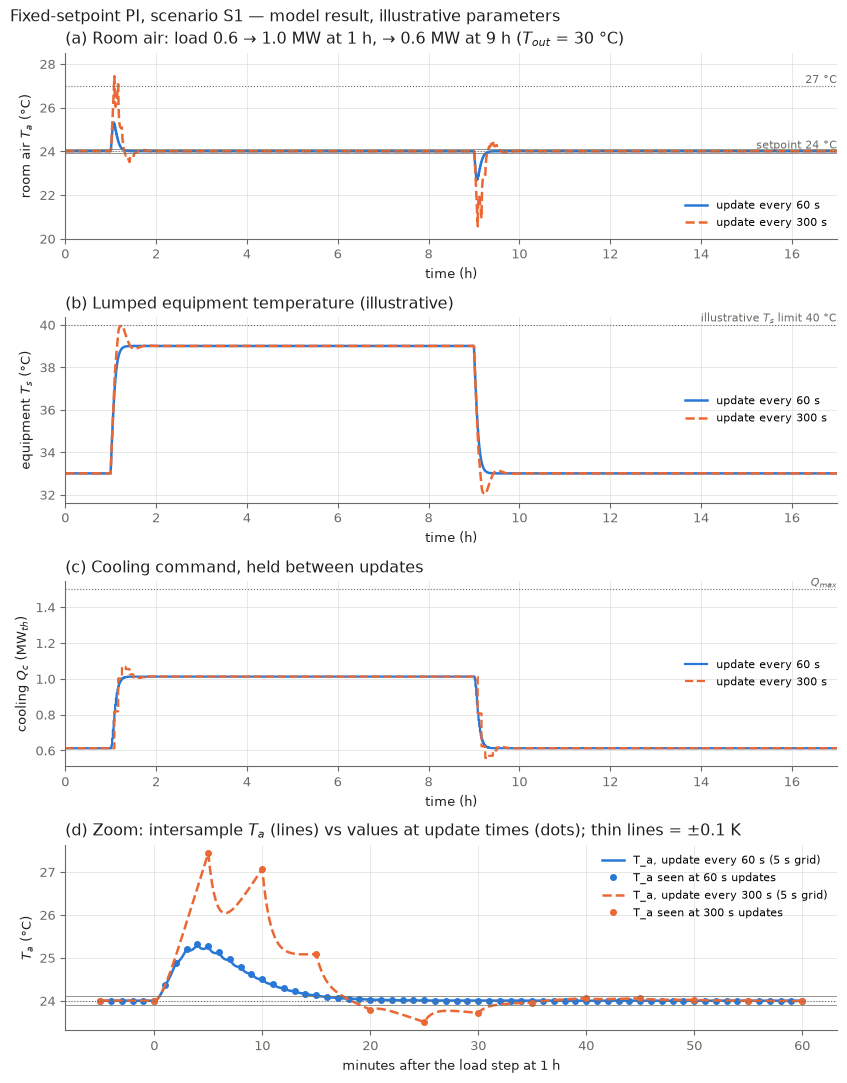

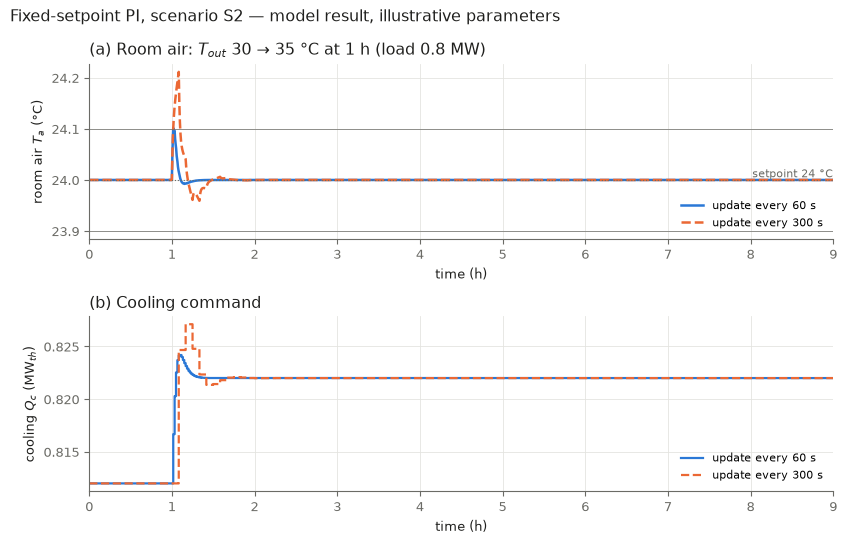

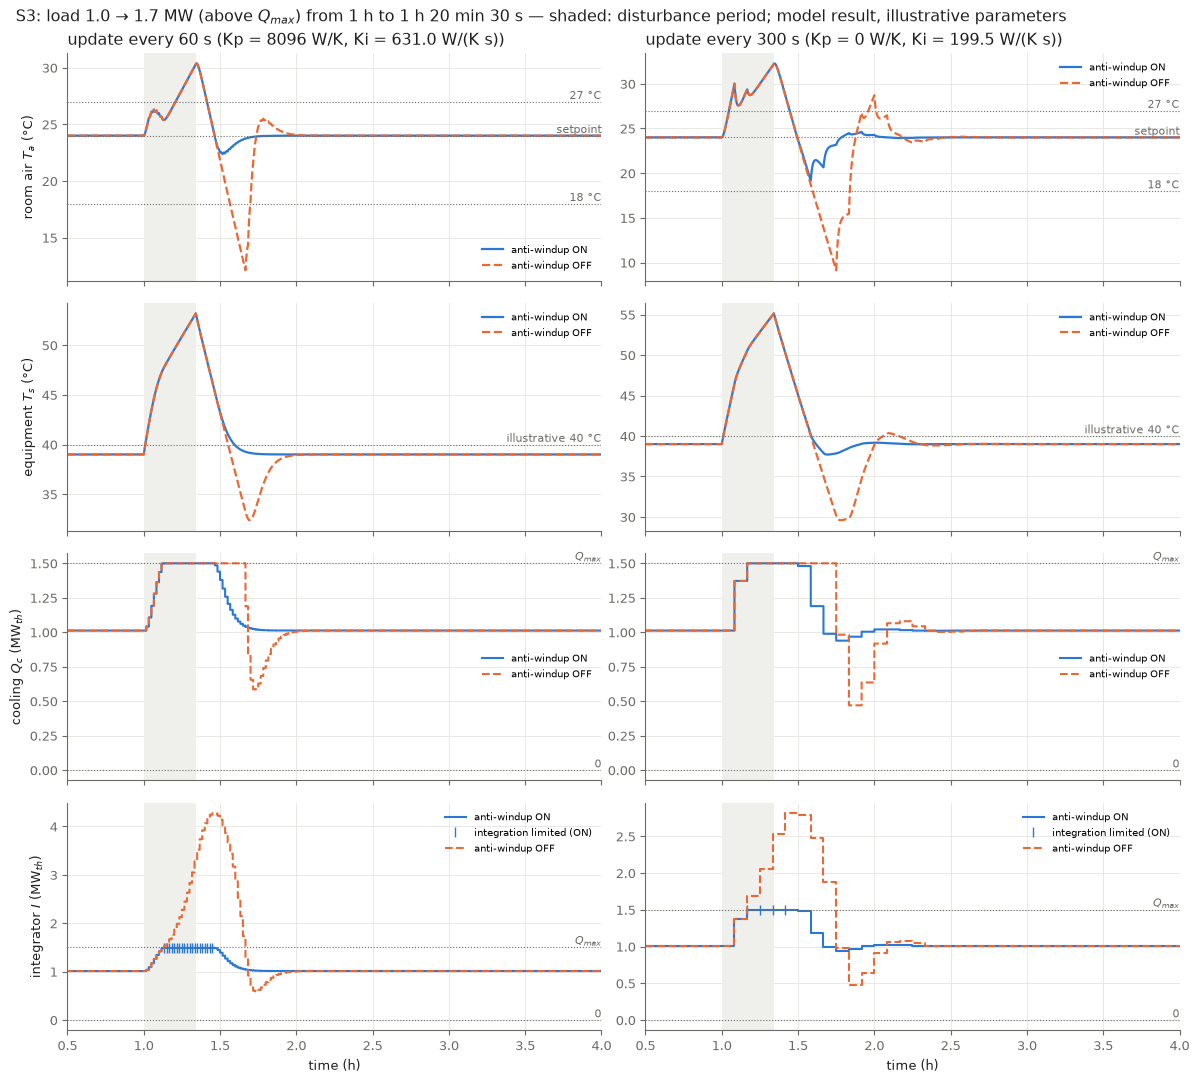

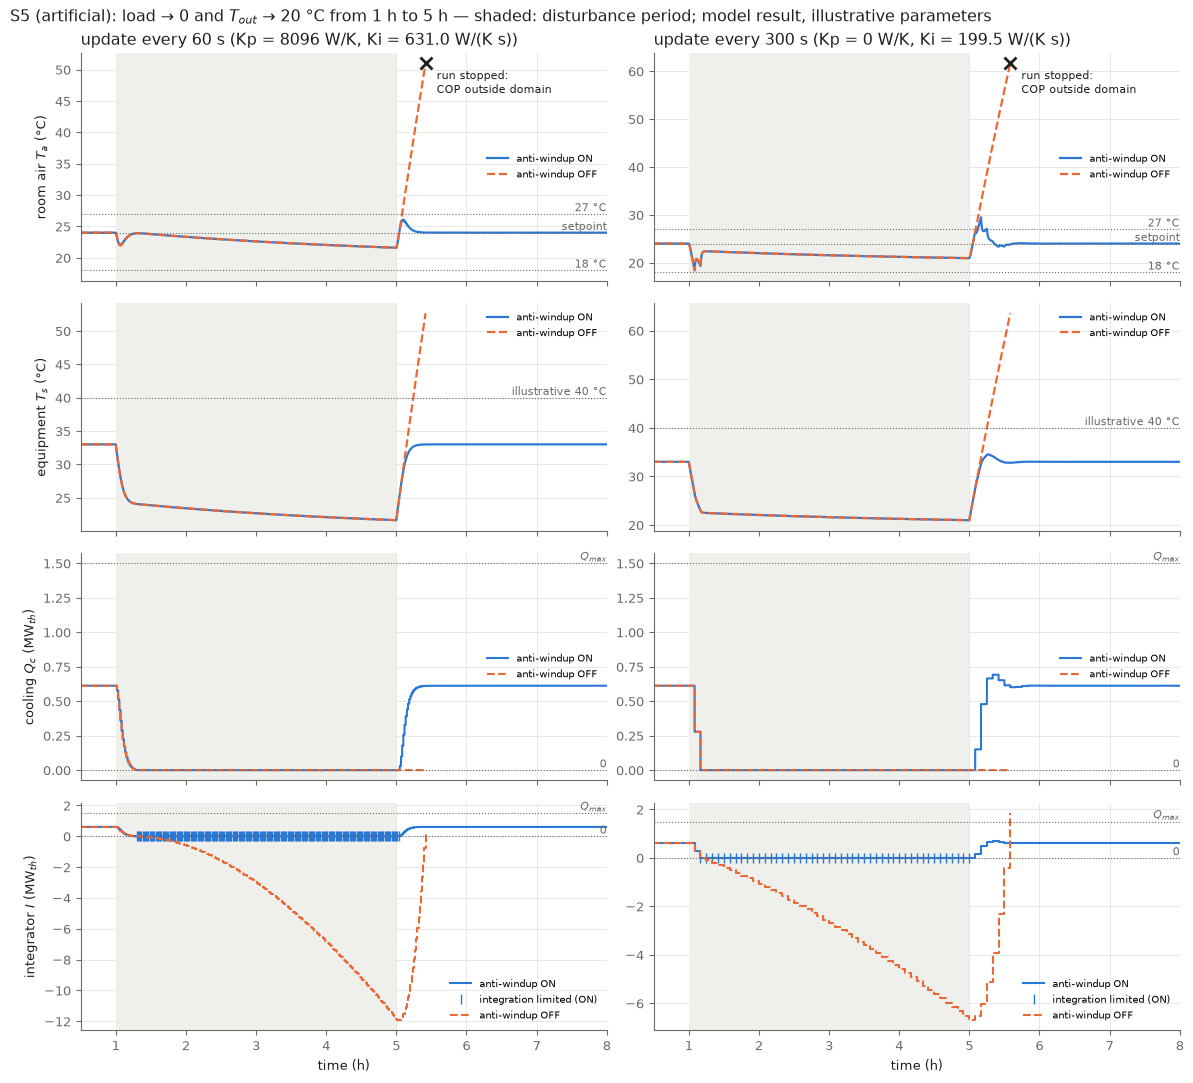

saved: fig02_pi_load_sequence.png fig03_pi_outdoor_step.png fig04_pi_overload_antiwindup.png fig05_pi_lowsat_antiwindup.png


In [9]:
BLUE, ORANGE, INK, MUTED, GRID, SPAN = "#2a78d6", "#eb6834", "#1f1f1d", "#6b6b66", "#e4e4e0", "#efefec"
plt.rcParams.update({"font.size": 9.5, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})


def style(ax):
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)


def hline(ax, y, txt, x_text):
    ax.axhline(y, color=MUTED, lw=0.8, ls=":")
    if txt:
        ax.text(x_text, y, " " + txt, color=MUTED, fontsize=8, va="bottom", ha="right")


def mark_stop(ax, res, y):
    if res.status != "completed":
        ax.plot(res.t[-1] / H, y, marker="x", color=INK, ms=8, mew=2)
        ax.annotate("run stopped:\nCOP outside domain", (res.t[-1] / H, y), xytext=(8, -4), textcoords="offset points",
                    fontsize=8, color=INK, va="top")


# ---- Figure 2: load sequence, both sample periods
fig, axs = plt.subplots(4, 1, figsize=(8.5, 11), sharex=False)
for dt, col, ls in ((60, BLUE, "-"), (300, ORANGE, "--")):
    r = R[("S1", dt, True)]
    th = r.t / H
    axs[0].plot(th, r.X[:, 1], color=col, ls=ls, lw=1.8, label=f"update every {dt} s")
    axs[1].plot(th, r.X[:, 0], color=col, ls=ls, lw=1.8, label=f"update every {dt} s")
    axs[2].step(th, r.Q / 1e6, where="post", color=col, ls=ls, lw=1.6, label=f"update every {dt} s")
    z = (r.t >= 1*H - 300) & (r.t <= 1*H + 3600)
    axs[3].plot((r.t[z] - H) / 60, r.X[z, 1], color=col, ls=ls, lw=1.8, label=f"T_a, update every {dt} s (5 s grid)")
    lz = (r.log["t"] >= H - 300) & (r.log["t"] <= 2 * H)
    axs[3].plot((r.log["t"][lz] - H) / 60, r.log["T_a"][lz], ls="none", marker="o", ms=4, color=col,
                label=f"T_a seen at {dt} s updates")
for ax in axs[:3]:
    ax.set_xlim(0, 17); ax.set_xlabel("time (h)")
hline(axs[0], T_SET, "setpoint 24 °C", 17); hline(axs[0], 27.0, "27 °C", 17)
for y in (T_SET - TOL, T_SET + TOL):
    axs[0].axhline(y, color=MUTED, lw=0.5)
axs[0].set_ylabel("room air $T_a$ (°C)"); axs[0].set_ylim(20, 28.5)
axs[0].set_title("(a) Room air: load 0.6 → 1.0 MW at 1 h, → 0.6 MW at 9 h ($T_{out}$ = 30 °C)", loc="left", color=INK)
hline(axs[1], 40.0, "illustrative $T_s$ limit 40 °C", 17)
axs[1].set_ylabel("equipment $T_s$ (°C)"); axs[1].set_title("(b) Lumped equipment temperature (illustrative)", loc="left", color=INK)
hline(axs[2], p.Q_max / 1e6, "$Q_{max}$", 17)
axs[2].set_ylabel("cooling $Q_c$ (MW$_{th}$)"); axs[2].set_title("(c) Cooling command, held between updates", loc="left", color=INK)
hline(axs[3], T_SET, "", 0)
for y in (T_SET - TOL, T_SET + TOL):
    axs[3].axhline(y, color=MUTED, lw=0.5)
axs[3].set_xlabel("minutes after the load step at 1 h"); axs[3].set_ylabel("$T_a$ (°C)")
axs[3].set_title("(d) Zoom: intersample $T_a$ (lines) vs values at update times (dots); thin lines = ±0.1 K", loc="left", color=INK)
for ax in axs:
    style(ax)
for ax, loc in zip(axs, ("lower right", "center right", "center right", "upper right")):
    ax.legend(frameon=False, fontsize=8, loc=loc)
fig.suptitle("Fixed-setpoint PI, scenario S1 — model result, illustrative parameters", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig02_pi_load_sequence.png", dpi=150); plt.show()

# ---- Figure 3: outdoor-temperature step
fig, axs = plt.subplots(2, 1, figsize=(8.5, 5.5))
for dt, col, ls in ((60, BLUE, "-"), (300, ORANGE, "--")):
    r = R[("S2", dt, True)]
    axs[0].plot(r.t / H, r.X[:, 1], color=col, ls=ls, lw=1.8, label=f"update every {dt} s")
    axs[1].step(r.t / H, r.Q / 1e6, where="post", color=col, ls=ls, lw=1.6, label=f"update every {dt} s")
hline(axs[0], T_SET, "setpoint 24 °C", 9)
for y in (T_SET - TOL, T_SET + TOL):
    axs[0].axhline(y, color=MUTED, lw=0.5)
axs[0].set_ylabel("room air $T_a$ (°C)"); axs[0].set_title("(a) Room air: $T_{out}$ 30 → 35 °C at 1 h (load 0.8 MW)", loc="left", color=INK)
axs[1].set_ylabel("cooling $Q_c$ (MW$_{th}$)"); axs[1].set_title("(b) Cooling command", loc="left", color=INK)
for ax in axs:
    ax.set_xlim(0, 9); ax.set_xlabel("time (h)"); style(ax); ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Fixed-setpoint PI, scenario S2 — model result, illustrative parameters", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig03_pi_outdoor_step.png", dpi=150); plt.show()


# ---- Figures 4 and 5: saturation with anti-windup on/off, both sample periods
def saturation_figure(sid, fname, title, xlim, span):
    fig, axs = plt.subplots(4, 2, figsize=(12, 11), sharex="col")
    for j, dt in enumerate((60, 300)):
        for aw, col, ls, lab in ((True, BLUE, "-", "anti-windup ON"), (False, ORANGE, "--", "anti-windup OFF")):
            r = R[(sid, dt, aw)]
            th = r.t / H
            axs[0, j].plot(th, r.X[:, 1], color=col, ls=ls, lw=1.6, label=lab)
            mark_stop(axs[0, j], r, r.X[-1, 1])
            axs[1, j].plot(th, r.X[:, 0], color=col, ls=ls, lw=1.6, label=lab)
            axs[2, j].step(th, r.Q / 1e6, where="post", color=col, ls=ls, lw=1.5, label=lab)
            axs[3, j].step(r.log["t"] / H, r.log["I"] / 1e6, where="post", color=col, ls=ls, lw=1.5, label=lab)
            blk = r.log["limited"]
            if blk.any():
                axs[3, j].plot(r.log["t"][blk] / H, r.log["I"][blk] / 1e6, ls="none", marker="|", ms=7, color=col,
                               label=f"integration limited ({lab.split()[1]})")
        for ax in axs[:, j]:
            ax.axvspan(*span, color=SPAN, lw=0)
            ax.set_xlim(*xlim); style(ax)
        hline(axs[0, j], T_SET, "setpoint", xlim[1]); hline(axs[0, j], 27.0, "27 °C", xlim[1]); hline(axs[0, j], 18.0, "18 °C", xlim[1])
        hline(axs[1, j], 40.0, "illustrative 40 °C", xlim[1])
        for ax in axs[2:, j]:
            hline(ax, p.Q_max / 1e6, "$Q_{max}$", xlim[1]); hline(ax, 0.0, "0", xlim[1])
        axs[0, j].set_title(f"update every {dt} s (Kp = {GAINS[dt].Kp:.0f} W/K, Ki = {GAINS[dt].Ki:.1f} W/(K s))", loc="left", color=INK)
        axs[3, j].set_xlabel("time (h)")
    axs[0, 0].set_ylabel("room air $T_a$ (°C)"); axs[1, 0].set_ylabel("equipment $T_s$ (°C)")
    axs[2, 0].set_ylabel("cooling $Q_c$ (MW$_{th}$)"); axs[3, 0].set_ylabel("integrator $I$ (MW$_{th}$)")
    for ax in axs.flat:
        ax.legend(frameon=False, fontsize=7.5, loc="best")
    fig.suptitle(title + " — shaded: disturbance period; model result, illustrative parameters", x=0.01, ha="left", color=INK)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=150); plt.show()


saturation_figure("S3", "fig04_pi_overload_antiwindup.png",
                  "S3: load 1.0 → 1.7 MW (above $Q_{max}$) from 1 h to 1 h 20 min 30 s", (0.5, 4.0), (1.0, 4830 / H))
saturation_figure("S5", "fig05_pi_lowsat_antiwindup.png",
                  "S5 (artificial): load → 0 and $T_{out}$ → 20 °C from 1 h to 5 h", (0.5, 8.0), (1.0, 5.0))
print("saved:", *sorted(x.name for x in FIG_DIR.glob("fig0[2-5]*.png")))

### Interpretation
<div style="background:#fdf6e3;border-left:6px solid #c98500;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>What the results show (model behaviour, illustrative parameters; no energy or safety claims)</b><br>
<ol>
<li><b>The update interval changes which gains work.</b>
<ul>
<li>At 60 s the rule selects $K_p\approx 8.1$ kW/K and $K_i\approx 631$ W/(K·s), with largest pole magnitude 0.686.</li>
<li>The <i>same</i> gains at 300 s give a pole at 2.71: the loop is unstable. Run on S1, that loop hit both cooling limits and left the COP domain after 1.25 h.</li>
<li>Retuned for 300 s, the rule picks integral action only ($K_p=0$, $K_i\approx 200$ W/(K·s)), with largest pole magnitude 0.565. Its margin is thinner: with both gains doubled the largest pole is 0.918, against 0.828 at 60 s.</li>
</ul></li>
<li><b>Tracking, S1 load step (0.4 MW).</b>
<ul>
<li>At 60 s: peak +1.32 K, no overshoot, inside ±0.1 K after 15.5 min, no limit violations.</li>
<li>At 300 s: peak +3.44 K and overshoot 0.50 K, settling after 31.7 min. $T_a$ briefly reaches 27.44 °C, above the 27 °C band edge for about 0.02 h, and $T_s$ peaks at 39.97 °C.</li>
<li>So, with these illustrative parameters, a 300 s update interval is <b>not adequate</b> for this load step. This is the L2 check the spec asked for.</li>
<li>The residual error after settling is about $10^{-11}$ K. That is round-off level, not literally zero.</li>
</ul></li>
<li><b>Outdoor step, S2.</b> This is a small disturbance: only $UA_e\times5$ K = 10 kW. Peaks are 0.10 K (60 s) and 0.21 K (300 s); settling takes 1.2 and 6.1 min.</li>
<li><b>Intersample matters under overload.</b>
<ul>
<li>In S1 the peaks happen just before updates, so update-time samples catch them.</li>
<li>In S4 at 300 s, the update-time samples show 32.6 °C, but the fine-grid maximum is 36.7 °C.</li>
</ul></li>
<li><b>Overload above capacity, S3 (1.7 MW, with $Q_{\max}$ = 1.5 MW).</b>
<ul>
<li>Cooling sits at $Q_{\max}$ for the whole overload at both intervals, so no setting of this controller could remove more heat during it.</li>
<li>The illustrative limits are violated: $T_a$ peaks at 30.4 °C (60 s) and 32.3 °C (300 s), and $T_s$ at 53.2 and 55.2 °C, above 40 °C for about 0.6 h.</li>
<li><b>With anti-windup:</b> the integrator stays at about $Q_{\max}$, and cooling leaves saturation as soon as the error reverses. Undershoot afterwards is 1.6 K (60 s) and 4.9 K (300 s); settling takes 23 and 41 min.</li>
<li><b>Without anti-windup:</b> the integrator winds up to 4.3 and 2.8 MW, and cooling stays at maximum 12–15 min longer. $T_a$ undershoots to 12.1 and 9.1 °C (below 18 °C), and settling takes 38 and 65 min.</li>
</ul></li>
<li><b>Severe overload, S4 (2.0 MW).</b> $T_a$ reaches about 36.6–36.7 °C. At that point the COP model leaves its valid domain (t ≈ 1.24–1.27 h), so the run is <b>stopped and the error logged</b>. Nothing after that point is reported.</li>
<li><b>Lower saturation, S5 (artificial).</b>
<ul>
<li><b>With anti-windup:</b> cooling is off for about 4 h with the integrator held near 0. When the load returns, $T_a$ overshoots to 26.1 °C (60 s) and 29.5 °C (300 s, above 27 °C for about 0.07 h), settling after 18.5 and 36 min.</li>
<li><b>Without anti-windup:</b> the integrator winds down to −11.9 and −6.7 MW. Cooling stays off after the load returns, $T_a$ climbs past 50 °C, and the run stops when the COP leaves its domain.</li>
</ul></li>
<li><b>A bug these tests caught.</b> The first draft of the anti-windup rejected the <i>whole</i> integrator update at a limit. With $K_p=0$, that froze the integrator just inside the limit: cooling stayed on while the room was far too cold, and stayed below $Q_{\max}$ while it overheated. The fix clamps integration at the limit. Unit test AW5 and the closed-loop invariant check now guard against it.</li>
</ol>
<b>Not shown here.</b>
<ul>
<li>Energy use or savings: no COP-weighted electricity is computed.</li>
<li>Robustness to parameter error: the gain-margin test only scales the gains.</li>
<li>Actuator ramp limits or a minimum chiller capacity.</li>
<li>Whether $m$ = 1 K is the right margin.</li>
</ul>

</div>

## 8. Summary (copyable)

In [10]:
groups = [
    ("Anti-windup logic (unit tests, both directions)", r"AW\d"),
    ("Closed-loop poles inside unit circle (+ gain margin 2)", r"P\d"),
    ("Consistent initialization", r"I1"),
    ("Linear pole model = simulator", r"L1"),
    ("Simulator vs independent solve_ivp replay", r"R1"),
    ("Energy balance in closed loop", r"E1"),
    ("Intersample grid refinement", r"G1"),
    ("Anti-windup in closed loop (on/off, invariant)", r"AW(c|off|inv)"),
    ("COP-domain stop logged (S4)", r"COP"),
]
lines = ["STAGE 2 (FIXED-SETPOINT PI) VERIFICATION SUMMARY (fresh kernel)", "-" * 72]
used = set()
for name, pat in groups:
    rows = [r for r in results if re.match(pat + r"(-|$)", r[0])]
    used |= {r[0] for r in rows}
    n_ok = sum(r[4] for r in rows)
    lines.append(f"{'PASS' if rows and n_ok == len(rows) else 'FAIL'}  {name:58s} {n_ok:2d}/{len(rows):2d}")
assert used == {r[0] for r in results}, "ungrouped checks"
lines.append("-" * 72)
lines.append(f"TOTAL {sum(r[4] for r in results)}/{len(results)} checks passed")
lines.append("")
lines.append(f"Setpoint T_set = {T_SET:.2f} degC; tolerance +/-{TOL} K; Q_c in [0, {p.Q_max/1e6:.2f}] MW_th")
for dt, g in GAINS.items():
    lines.append(f"dt = {dt:3d} s: Kp = {g.Kp:9.1f} W/K, Ki = {g.Ki:8.2f} W/(K s), spectral radius {ct.spectral_radius(p, g):.4f}")
lines.append("")
lines += [f"FINDING {fid}: {txt}" for fid, txt in findings]
lines.append("")
lines += TXT
print("\n".join(lines))

STAGE 2 (FIXED-SETPOINT PI) VERIFICATION SUMMARY (fresh kernel)
------------------------------------------------------------------------
PASS  Anti-windup logic (unit tests, both directions)             8/ 8
PASS  Closed-loop poles inside unit circle (+ gain margin 2)      4/ 4
PASS  Consistent initialization                                   2/ 2
PASS  Linear pole model = simulator                               2/ 2
PASS  Simulator vs independent solve_ivp replay                   4/ 4
PASS  Energy balance in closed loop                               2/ 2
PASS  Intersample grid refinement                                 2/ 2
PASS  Anti-windup in closed loop (on/off, invariant)             10/10
PASS  COP-domain stop logged (S4)                                 2/ 2
------------------------------------------------------------------------
TOTAL 36/36 checks passed

Setpoint T_set = 24.00 degC; tolerance +/-0.1 K; Q_c in [0, 1.50] MW_th
dt =  60 s: Kp =    8096.1 W/K, Ki =   630.96 W/(K s